# GARCÍA HERNÁNDEZ RODRIGO | 23070447
# EXAMEN PRÁCTICO UNIDAD 2

# INSTRUCCIONES
1.	Baje la BD
2.	Limpie los datos.
3.	La base de datos ya trae los tweets clasificados. Encuentre que aerolínea es la que tiene más quejas usando gráficas.
4.	Enseguida investigue que departamento es el que genera las quejas haga gráficas
5.	Investigue si el día de la semana es un actor determinante para las quejas o existe otro motivo.
6.	Finalmente agregue sus conclusiones de lo que observa.


# 1. Baje la BD

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import re
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.sentiment.vader import SentimentIntensityAnalyzer


nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('vader_lexicon')

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [1]:
import pandas as pd
tweetsEx = pd.read_csv('/kaggle/input/datasets/rodrigogarciah/tweetsexamen/Tweets.csv')

print(tweetsEx)

                 tweet_id airline_sentiment  airline_sentiment_confidence  \
0      570306133677760513           neutral                        1.0000   
1      570301130888122368          positive                        0.3486   
2      570301083672813571           neutral                        0.6837   
3      570301031407624196          negative                        1.0000   
4      570300817074462722          negative                        1.0000   
...                   ...               ...                           ...   
14635  569587686496825344          positive                        0.3487   
14636  569587371693355008          negative                        1.0000   
14637  569587242672398336           neutral                        1.0000   
14638  569587188687634433          negative                        1.0000   
14639  569587140490866689           neutral                        0.6771   

               negativereason  negativereason_confidence         airline  \

In [4]:
tweetsEx.sample(15)

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
7529,569542242983124992,positive,1.0000,NaN,NaN,Delta,NaN,sandyy889,NaN,0,@JetBlue Landing! As usual great flight wiyh a...,NaN,2015-02-22 09:00:26 -0800,NaN,America/Detroit
11011,568617305757728768,negative,1.0000,Late Flight,1.0000,US Airways,NaN,masonkesner,NaN,0,"@USAirways Flights 890 was the delay, Flight 5...","[0.0, 0.0]",2015-02-19 19:45:04 -0800,"Arkansas, USA",Central Time (US & Canada)
7253,569739521291452416,negative,1.0000,Late Flight,1.0000,Delta,NaN,maykaynvwd,NaN,0,@JetBlue Woo! Update! Flight 915 is now possib...,NaN,2015-02-22 22:04:21 -0800,NaN,NaN
7286,569687874288914432,negative,1.0000,Customer Service Issue,0.3439,Delta,NaN,HayesGirl_,NaN,0,@JetBlue i only take jetblue to travel and i h...,NaN,2015-02-22 18:39:08 -0800,NaN,NaN
2822,568883475534745600,neutral,1.0000,NaN,NaN,United,NaN,dlm_3,NaN,0,@united dmangen@visualclubconcepts.com,NaN,2015-02-20 13:22:44 -0800,Global,Eastern Time (US & Canada)
5128,569321988591906818,negative,1.0000,Cancelled Flight,0.3453,Southwest,NaN,scoobydoo9749,NaN,0,@SouthwestAir coming up on 10 hrs and all at t...,"[39.1766101, -76.6700606]",2015-02-21 18:25:14 -0800,"Tallahassee, FL",America/Chicago
193,569298165855338497,positive,1.0000,NaN,NaN,Virgin America,NaN,lexiesalas,NaN,0,@VirginAmerica thanks!,NaN,2015-02-21 16:50:34 -0800,BAYAREA✈️NYC,Pacific Time (US & Canada)
12473,570175461298475008,negative,0.6753,Customer Service Issue,0.3494,American,NaN,AnnaIntheCity,NaN,0,@AmericanAir I know your policy. Just asking f...,NaN,2015-02-24 02:56:37 -0800,Northern Virginia,Eastern Time (US & Canada)
7893,569083132353204224,neutral,1.0000,NaN,NaN,Delta,NaN,JetBlueNews,NaN,0,@JetBlue Airways Lowered to Strong Sell at Vet...,NaN,2015-02-21 02:36:06 -0800,USA,Sydney
9038,570274057729519617,neutral,1.0000,NaN,NaN,US Airways,NaN,themainevent001,NaN,0,@USAirways is there a phone number or email ad...,NaN,2015-02-24 09:28:25 -0800,Saratoga Springs,NaN


# 2. Limpieza de datos

In [5]:
tweetsEx.columns

Index(['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence',
       'negativereason', 'negativereason_confidence', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold',
       'retweet_count', 'text', 'tweet_coord', 'tweet_created',
       'tweet_location', 'user_timezone'],
      dtype='object')

In [8]:
tweetsEx.isnull().sum()

tweet_id                            0
airline_sentiment                   0
airline_sentiment_confidence        0
negativereason                   5462
negativereason_confidence        4118
airline                             0
airline_sentiment_gold          14600
name                                0
negativereason_gold             14608
retweet_count                       0
text                                0
tweet_coord                     13621
tweet_created                       0
tweet_location                   4733
user_timezone                    4820
dtype: int64

In [12]:
columnasEliminar = ['tweet_id', 'retweet_count', 'airline_sentiment_gold', 'negativereason_gold', 'tweet_coord', 'tweet_location', 'user_timezone', 'name'
]

tweetsEx = tweetsEx.drop(columns=columnasEliminar)
print(tweetsEx)


KeyError: "['tweet_id', 'retweet_count', 'airline_sentiment_gold', 'negativereason_gold', 'tweet_coord', 'tweet_location', 'user_timezone', 'name'] not found in axis"

In [14]:
tweetsEx.sample(10)

,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,text,tweet_created
2141,negative,1.0000,Late Flight,0.6787,United,@united the drunk guy you threw out of flight ...,2015-02-21 19:39:47 -0800
13433,negative,0.6438,Cancelled Flight,0.3406,American,@AmericanAir Thanks. Took care of it. Issue wa...,2015-02-23 06:22:32 -0800
13716,negative,1.0000,Cancelled Flight,1.0000,American,@AmericanAir I understand the weather issues. ...,2015-02-22 21:57:03 -0800
11705,positive,1.0000,NaN,NaN,US Airways,@USAirways Thank you. And thanks for being so ...,2015-02-17 13:56:04 -0800
2538,negative,1.0000,Customer Service Issue,0.6536,United,"@united It isnt simple issue, generally how yo...",2015-02-21 04:48:17 -0800
9300,neutral,1.0000,NaN,NaN,US Airways,@USAirways but question : if the downgrade in...,2015-02-23 14:53:09 -0800
5982,negative,1.0000,longlines,0.3368,Southwest,@SouthwestAir please hire an efficiency consul...,2015-02-19 08:32:04 -0800
12685,negative,1.0000,Customer Service Issue,1.0000,American,@AmericanAir This is getting out of hand. I ca...,2015-02-23 19:30:10 -0800
5348,negative,0.6809,Customer Service Issue,0.6809,Southwest,@SouthwestAir- I called @united and they solve...,2015-02-21 08:39:49 -0800
4168,negative,1.0000,Late Flight,0.6670,United,"@united sorry, I hate united. i won't get to s...",2015-02-17 13:27:11 -0800


# 3. Encuentre aerolínea con mas quejas

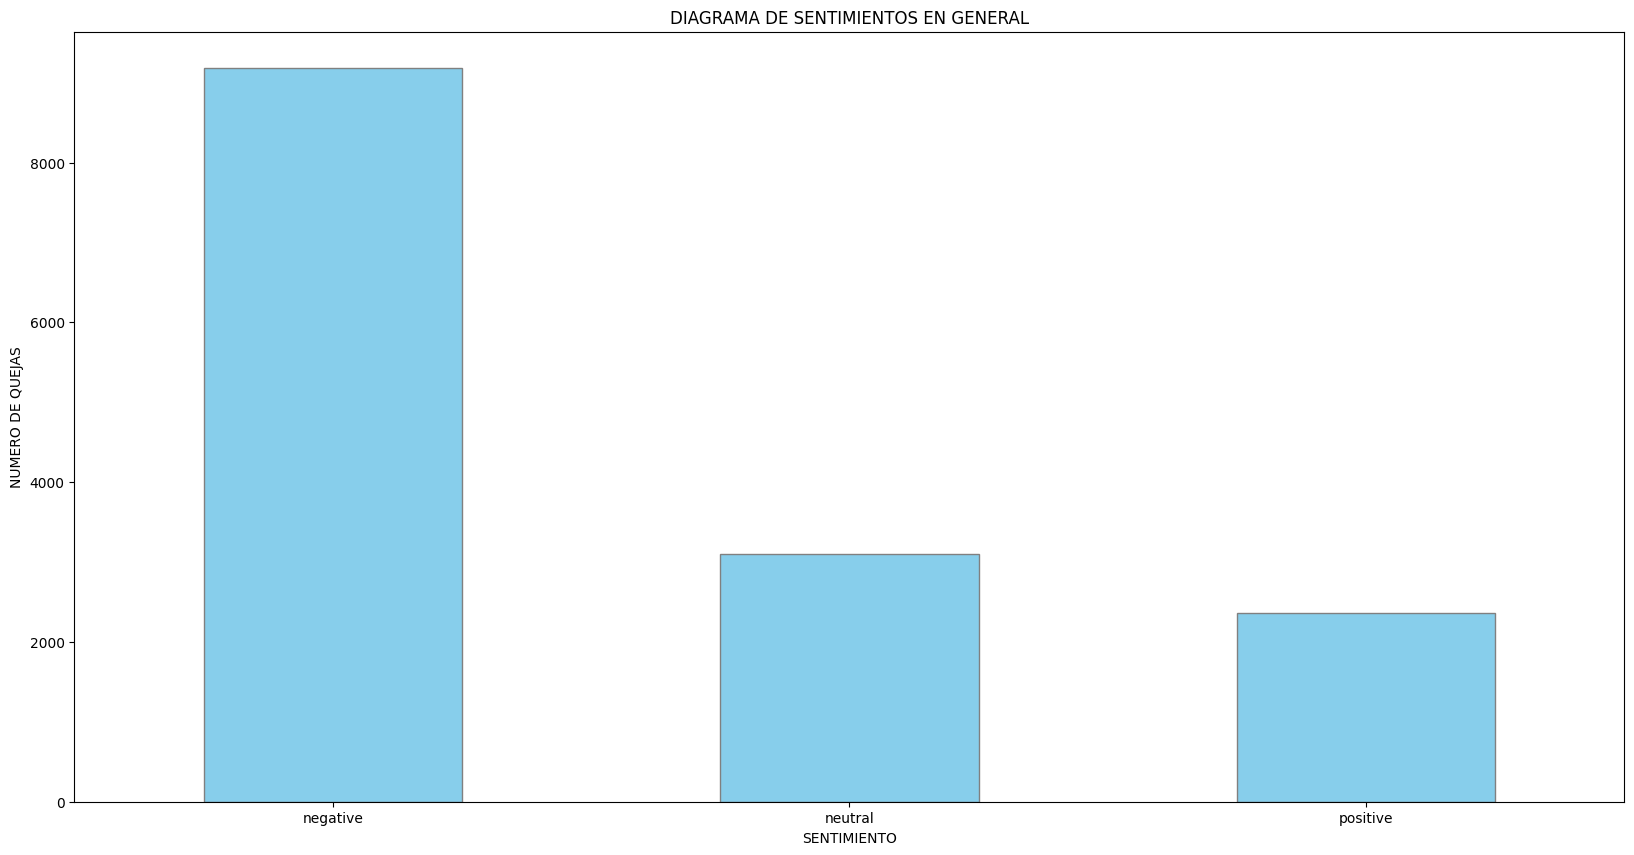

In [17]:
import matplotlib.pyplot as plt

conteoQuejas = tweetsEx["airline_sentiment"].value_counts().sort_index()
plt.figure(figsize=(20,10))
conteoQuejas.plot(kind="bar", color="skyblue", edgecolor="gray")

plt.title("DIAGRAMA DE SENTIMIENTOS EN GENERAL")
plt.xlabel("SENTIMIENTO")
plt.ylabel("NUMERO DE QUEJAS")
plt.xticks(rotation=0)
plt.show()

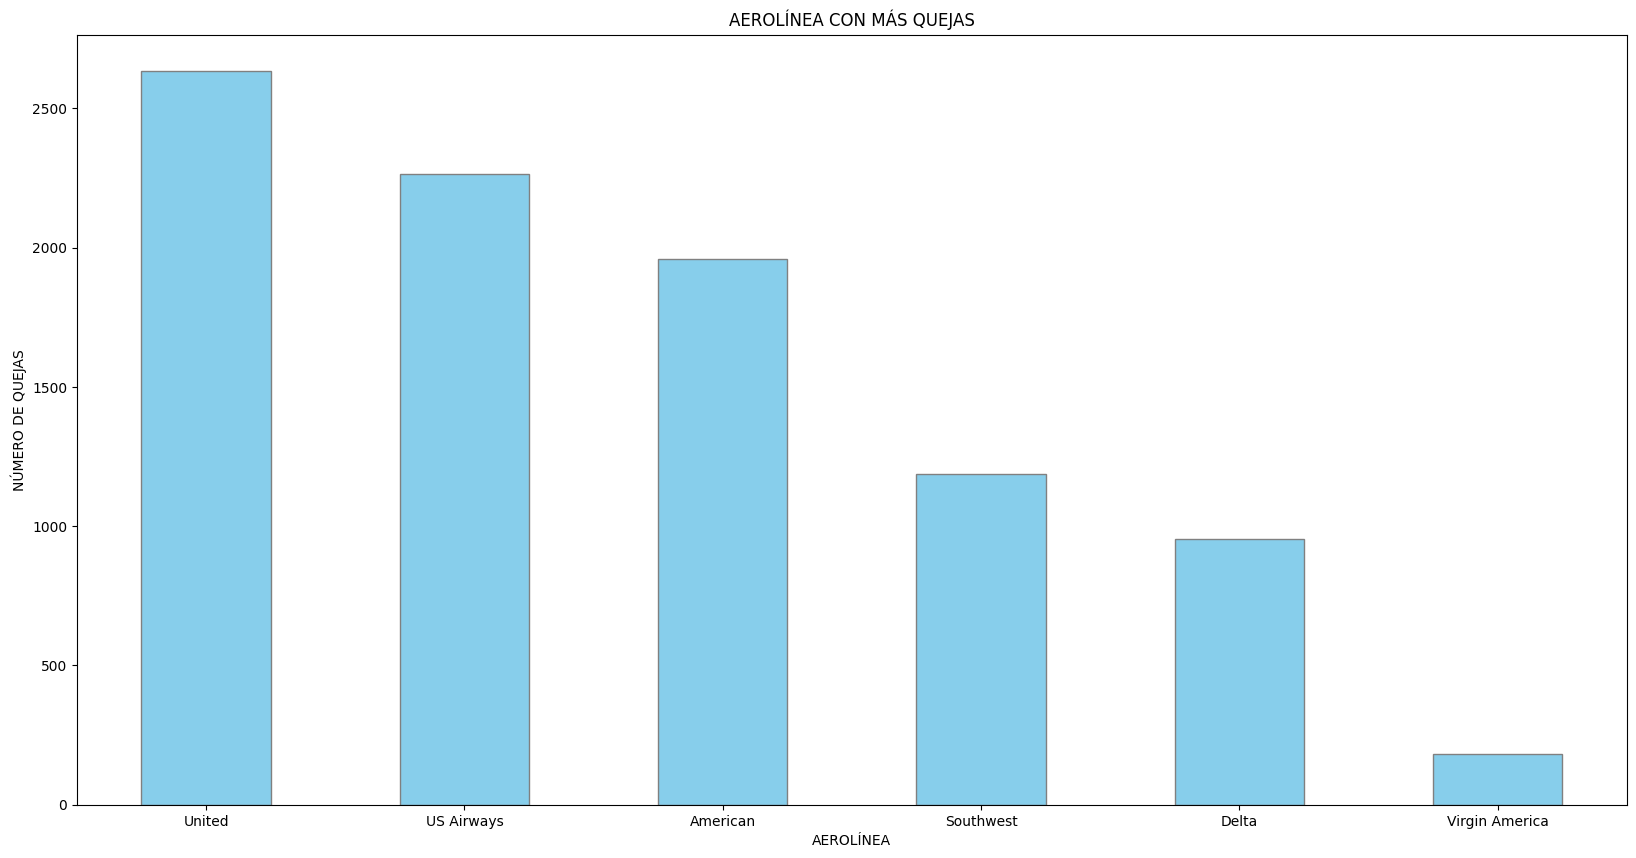

airline
United            2633
US Airways        2263
American          1960
Southwest         1186
Delta              955
Virgin America     181
Name: count, dtype: int64


In [22]:
tweets_negativos = tweetsEx[tweetsEx['airline_sentiment'] == 'negative']
conteoQuejas = tweets_negativos["airline"].value_counts()

plt.figure(figsize=(20, 10))
conteoQuejas.plot(kind="bar", color="skyblue", edgecolor="gray")

plt.title("AEROLÍNEA CON MÁS QUEJAS")
plt.xlabel("AEROLÍNEA")
plt.ylabel("NÚMERO DE QUEJAS")
plt.xticks(rotation=0)
plt.show()

print(conteoQuejas)

# 4. Que departamento recibe mas quejas

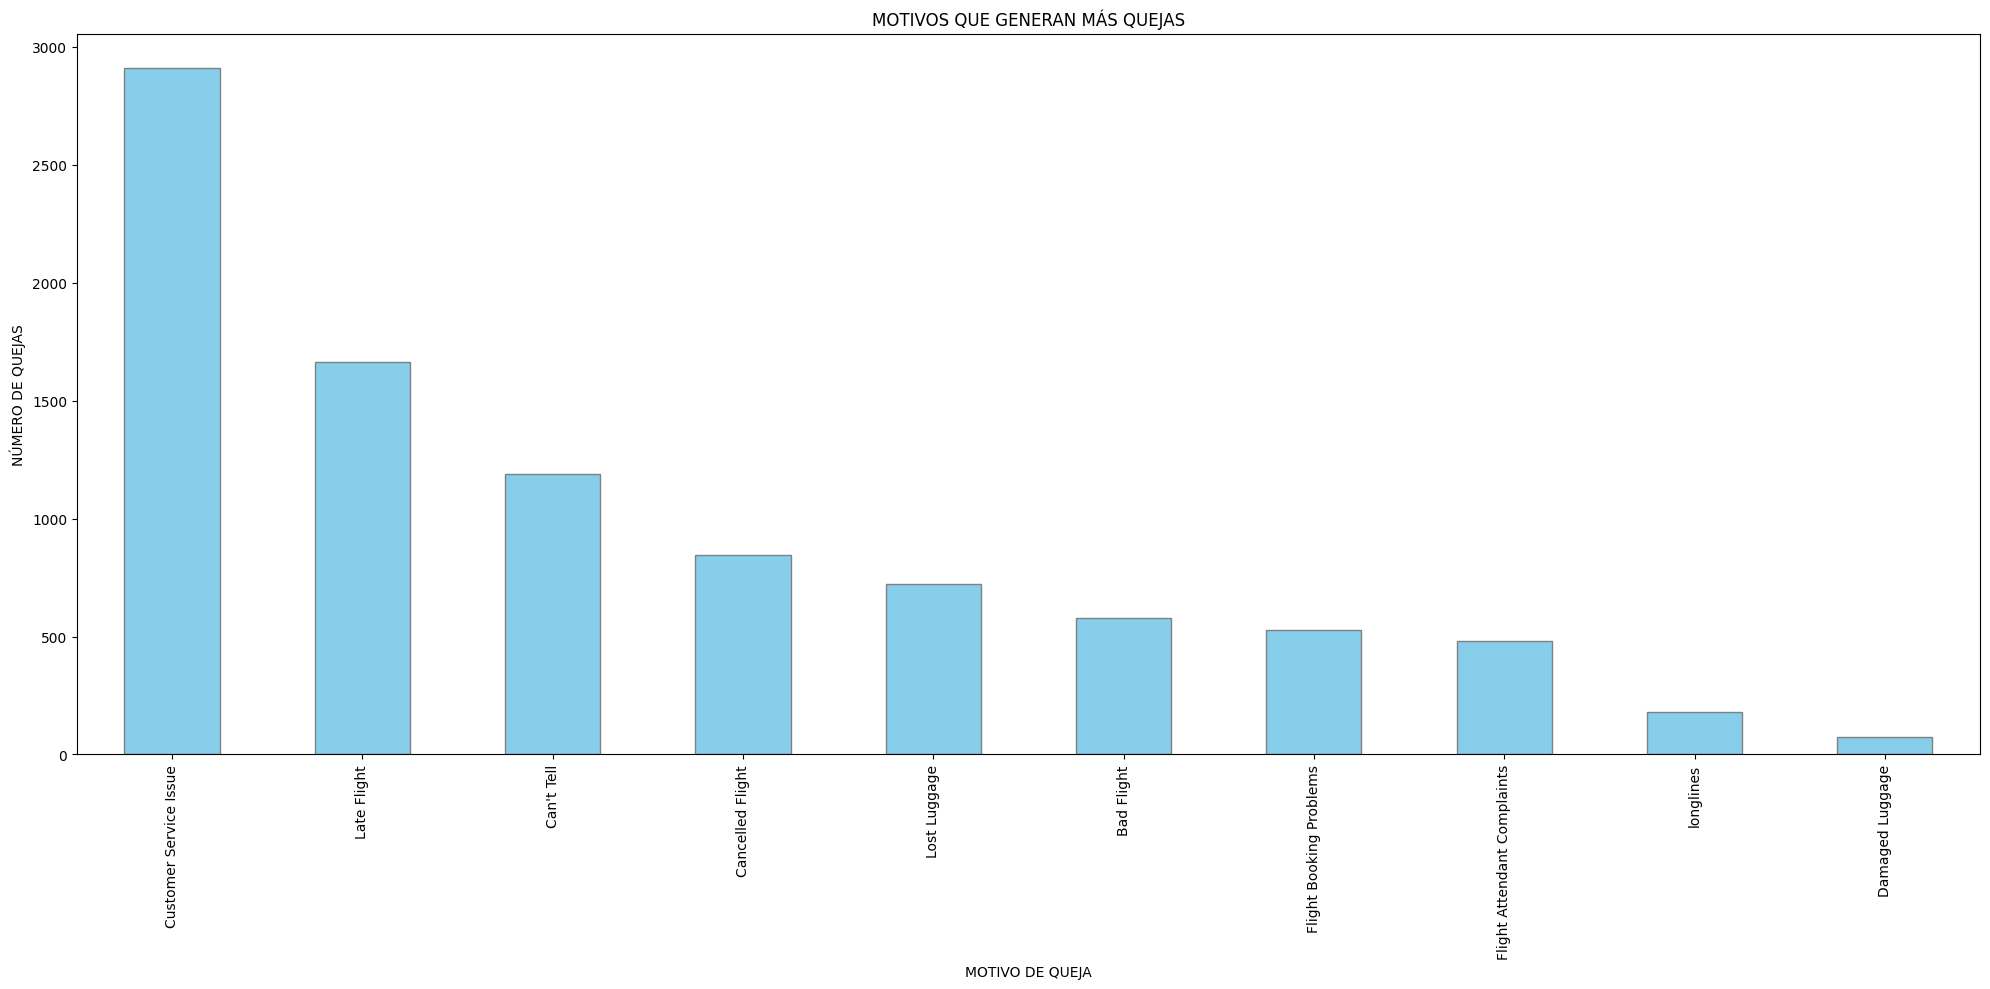

negativereason
Customer Service Issue         2910
Late Flight                    1665
Can't Tell                     1190
Cancelled Flight                847
Lost Luggage                    724
Bad Flight                      580
Flight Booking Problems         529
Flight Attendant Complaints     481
longlines                       178
Damaged Luggage                  74
Name: count, dtype: int64


In [26]:
import matplotlib.pyplot as plt
conteoDepartamentos = tweetsEx["negativereason"].value_counts()

plt.figure(figsize=(20, 10))
conteoDepartamentos.plot(kind="bar", color="skyblue", edgecolor="gray")

plt.title("MOTIVOS QUE GENERAN MÁS QUEJAS")
plt.xlabel("MOTIVO DE QUEJA")
plt.ylabel("NÚMERO DE QUEJAS")
plt.tight_layout()
plt.show()

print(conteoDepartamentos)

# 5. Dia de la semana es factor determinante para las quejas 

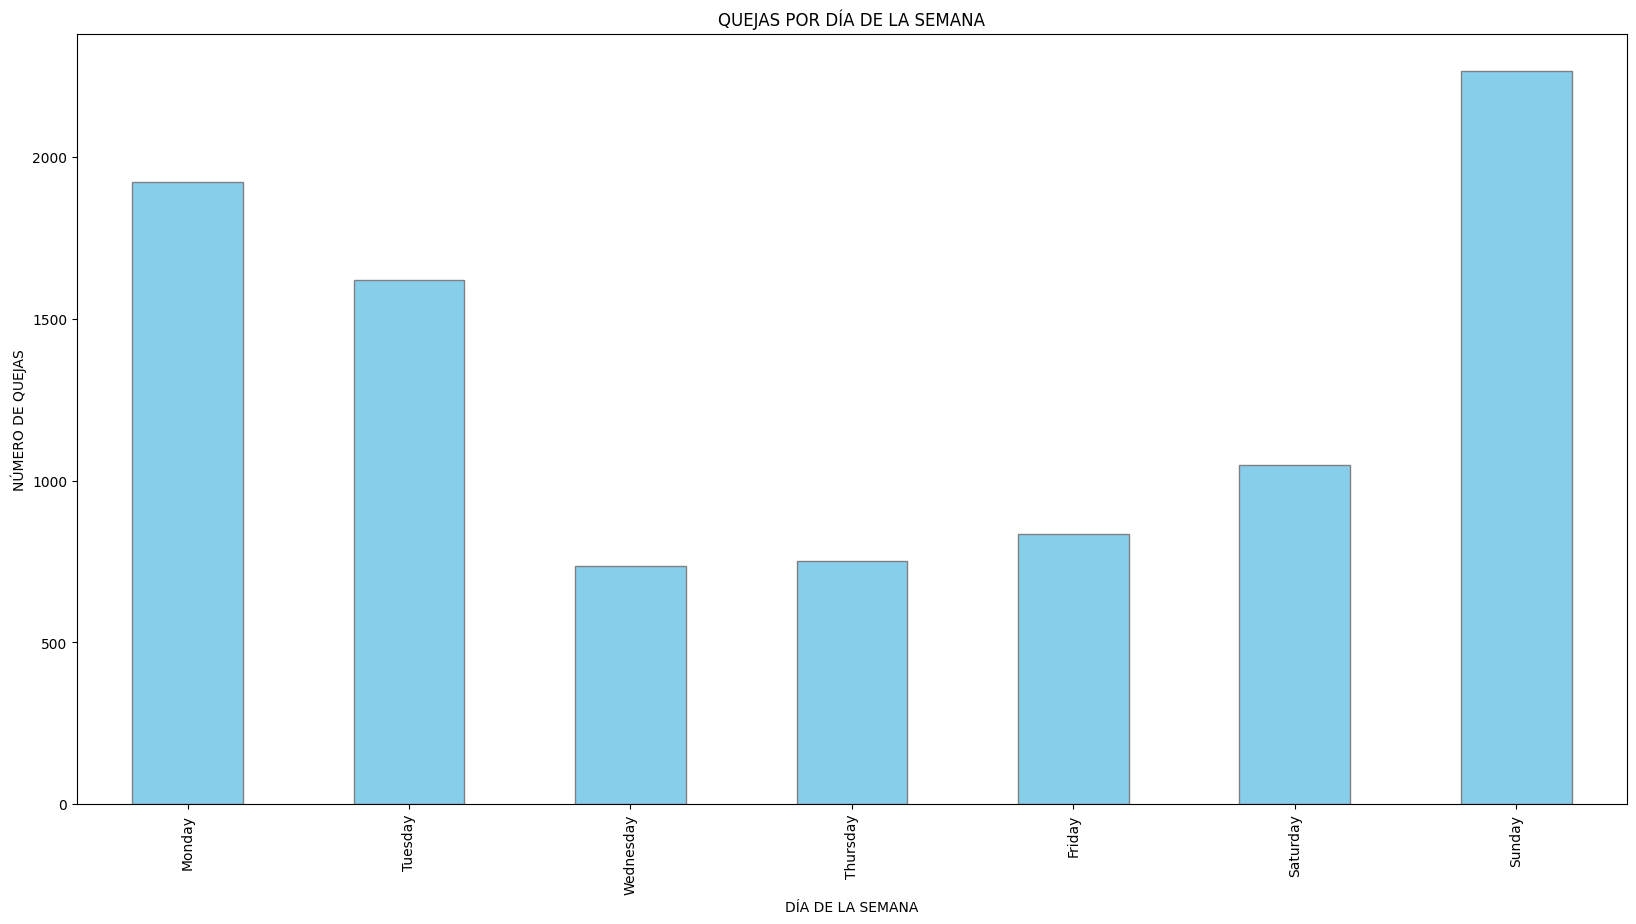

dia_semana
Monday       1922
Tuesday      1619
Wednesday     736
Thursday      751
Friday        835
Saturday     1049
Sunday       2266
Name: count, dtype: int64


In [29]:
tweetsEx['dia_semana'] = tweetsEx['tweet_created'].dt.day_name()

tweets_negativos = tweetsEx[tweetsEx['airline_sentiment'] == 'negative']

ordenDias = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
conteoDias = tweets_negativos['dia_semana'].value_counts().reindex(ordenDias)

plt.figure(figsize=(20, 10))
conteoDias.plot(kind="bar", color="skyblue", edgecolor="gray")

plt.title("QUEJAS POR DÍA DE LA SEMANA")
plt.xlabel("DÍA DE LA SEMANA")
plt.ylabel("NÚMERO DE QUEJAS")
plt.show()

print(conteoDias)

# 6. Conclusión

Podemos concluir que la aerolínea united es la que cuenta con mas quejas, el motivo de mas quejas son los problemas reportados por pasajeros en cuestión de servicio y el dia de la semana con mas quejas es el domingo debido al flujo inmenso de pasajeros la linea United no debe darse abasto con la cantidad de personas y requieren mas personal. 